# IT Support Analytics — Python & Pandas

This notebook analyzes IT support incident data exported from ServiceNow.
It covers data preparation, data-quality checks, business analysis, and
visualizations to identify incident patterns, workload, backlog, and
resolution-time trends.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
from google.colab import files

uploaded = files.upload()

Saving incident.csv to incident.csv


## 1. Load and Inspect the Dataset

In [7]:
df = pd.read_csv("incident.csv")

In [8]:
df.head()

,number,opened_at,caller_id,short_description,category,subcategory,impact,urgency,priority,state,assignment_group,assigned_to,resolved_at,closed_at
0,INC0008112,2019-07-29 11:48:43,survey user,Assessment : ATF Assessor,Inquiry / Help,NaN,3 - Low,3 - Low,5 - Planning,New,NaN,NaN,NaN,NaN
1,INC0008111,2019-07-22 14:04:57,System Administrator,ATF : Test1,Inquiry / Help,NaN,3 - Low,3 - Low,5 - Planning,New,NaN,NaN,NaN,NaN
2,INC0008001,2021-01-15 13:04:14,survey user,ATF:TEST2,Inquiry / Help,NaN,3 - Low,3 - Low,5 - Planning,New,NaN,NaN,NaN,NaN
3,INC0000050,2026-05-21 14:58:24,Jerrod Bennett,Can't access Exchange server - is it down?,Hardware,NaN,1 - High,1 - High,1 - Critical,In Progress,Hardware,Beth Anglin,NaN,NaN
4,INC0000046,2026-05-21 15:04:15,Bud Richman,Can't access SFA software,Software,NaN,1 - High,3 - Low,3 - Moderate,New,Software,NaN,NaN,NaN


In [9]:
df.shape

(70, 14)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70 entries, 0 to 69
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   number             70 non-null     object
 1   opened_at          70 non-null     object
 2   caller_id          70 non-null     object
 3   short_description  70 non-null     object
 4   category           66 non-null     object
 5   subcategory        6 non-null      object
 6   impact             70 non-null     object
 7   urgency            70 non-null     object
 8   priority           70 non-null     object
 9   state              70 non-null     object
 10  assignment_group   42 non-null     object
 11  assigned_to        48 non-null     object
 12  resolved_at        30 non-null     object
 13  closed_at          36 non-null     object
dtypes: object(14)
memory usage: 7.8+ KB


In [11]:
df.isnull().sum()

,0
number,0
opened_at,0
caller_id,0
short_description,0
category,4
subcategory,64
impact,0
urgency,0
priority,0
state,0


## 2. Data Preparation

In [12]:
df['opened_at'] = pd.to_datetime(df['opened_at'])
df['resolved_at'] = pd.to_datetime(df['resolved_at'])
df['closed_at'] = pd.to_datetime(df['closed_at'])

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70 entries, 0 to 69
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   number             70 non-null     object        
 1   opened_at          70 non-null     datetime64[ns]
 2   caller_id          70 non-null     object        
 3   short_description  70 non-null     object        
 4   category           66 non-null     object        
 5   subcategory        6 non-null      object        
 6   impact             70 non-null     object        
 7   urgency            70 non-null     object        
 8   priority           70 non-null     object        
 9   state              70 non-null     object        
 10  assignment_group   42 non-null     object        
 11  assigned_to        48 non-null     object        
 12  resolved_at        30 non-null     datetime64[ns]
 13  closed_at          36 non-null     datetime64[ns]
dtypes: datetime6

In [14]:
df['resolution_days'] = (
    df['resolved_at'] - df['opened_at']
).dt.total_seconds() / 86400

In [15]:
df[['number', 'opened_at', 'resolved_at', 'resolution_days']].head(10)

,number,opened_at,resolved_at,resolution_days
0,INC0008112,2019-07-29 11:48:43,NaT,NaN
1,INC0008111,2019-07-22 14:04:57,NaT,NaN
2,INC0008001,2021-01-15 13:04:14,NaT,NaN
3,INC0000050,2026-05-21 14:58:24,NaT,NaN
4,INC0000046,2026-05-21 15:04:15,NaT,NaN
5,INC0000019,2026-02-28 15:44:39,NaT,NaN
6,INC0000044,2026-03-13 17:47:08,NaT,NaN
7,INC0000001,2026-03-11 16:09:51,2026-06-11 12:56:12,91.865521
8,INC0009003,2018-08-30 02:17:32,2018-08-30 02:49:17,0.022049
9,INC0010003,2026-09-29 19:03:30,NaT,NaN


In [16]:
today = pd.Timestamp.today().normalize()

df['incident_age_days'] = (
    today - df['opened_at']
).dt.total_seconds() / 86400

In [17]:
df[['number', 'state', 'opened_at', 'incident_age_days']].head(10)

,number,state,opened_at,incident_age_days
0,INC0008112,New,2019-07-29 11:48:43,2627.507836
1,INC0008111,New,2019-07-22 14:04:57,2634.413229
2,INC0008001,New,2021-01-15 13:04:14,2091.455394
3,INC0000050,In Progress,2026-05-21 14:58:24,139.376111
4,INC0000046,New,2026-05-21 15:04:15,139.372049
5,INC0000019,In Progress,2026-02-28 15:44:39,221.343993
6,INC0000044,In Progress,2026-03-13 17:47:08,208.258935
7,INC0000001,Closed,2026-03-11 16:09:51,210.326493
8,INC0009003,Closed,2018-08-30 02:17:32,2960.904491
9,INC0010003,New,2026-09-29 19:03:30,8.205903


In [18]:
def classify_priority(priority):
    if priority in ['1 - Critical', '2 - High']:
        return 'High Priority'
    elif priority == '3 - Moderate':
        return 'Medium Priority'
    else:
        return 'Low Priority'

df['priority_group'] = df['priority'].apply(classify_priority)

In [19]:
df[['number', 'priority', 'priority_group']].head(10)

,number,priority,priority_group
0,INC0008112,5 - Planning,Low Priority
1,INC0008111,5 - Planning,Low Priority
2,INC0008001,5 - Planning,Low Priority
3,INC0000050,1 - Critical,High Priority
4,INC0000046,3 - Moderate,Medium Priority
5,INC0000019,2 - High,High Priority
6,INC0000044,2 - High,High Priority
7,INC0000001,1 - Critical,High Priority
8,INC0009003,3 - Moderate,Medium Priority
9,INC0010003,1 - Critical,High Priority


## 3. Data Quality Checks

In [21]:
df['number'].duplicated().sum()

np.int64(0)

In [22]:
df.duplicated().sum()

np.int64(0)

In [23]:
df['state'].value_counts()

,count
state,
Closed,28
In Progress,18
New,15
On Hold,7
Resolved,2


In [24]:
df['priority'].value_counts()

,count
priority,
1 - Critical,28
5 - Planning,18
3 - Moderate,13
4 - Low,6
2 - High,5


In [25]:
df['category'].value_counts(dropna=False)

,count
category,
Inquiry / Help,33
Software,13
Hardware,10
Network,8
NaN,4
Database,2


## 4. Business Analysis

In [26]:
# Incident count by category
category_counts = df['category'].value_counts(dropna=False)
print(category_counts)

# Incident count by priority
priority_counts = df['priority'].value_counts()
print(priority_counts)

# Incident count by assignment group
assignment_counts = df['assignment_group'].value_counts(dropna=False)
print(assignment_counts)

category
Inquiry / Help    33
Software          13
Hardware          10
Network            8
NaN                4
Database           2
Name: count, dtype: int64
priority
1 - Critical    28
5 - Planning    18
3 - Moderate    13
4 - Low          6
2 - High         5
Name: count, dtype: int64
assignment_group
NaN              28
Service Desk     12
Hardware          9
Software          9
Network           6
IT Securities     3
Database          2
Openspace         1
Name: count, dtype: int64


In [27]:
category_analysis = (
    df['category']
    .value_counts(dropna=False)
    .reset_index()
)

category_analysis.columns = ['category', 'incident_count']

category_analysis

,category,incident_count
0,Inquiry / Help,33
1,Software,13
2,Hardware,10
3,Network,8
4,NaN,4
5,Database,2


In [28]:
priority_analysis = (
    df['priority']
    .value_counts()
    .reset_index()
)

priority_analysis.columns = ['priority', 'incident_count']

priority_analysis

,priority,incident_count
0,1 - Critical,28
1,5 - Planning,18
2,3 - Moderate,13
3,4 - Low,6
4,2 - High,5


In [29]:
assignment_analysis = (
    df['assignment_group']
    .value_counts(dropna=False)
    .reset_index()
)

assignment_analysis.columns = ['assignment_group', 'incident_count']

assignment_analysis

,assignment_group,incident_count
0,NaN,28
1,Service Desk,12
2,Hardware,9
3,Software,9
4,Network,6
5,IT Securities,3
6,Database,2
7,Openspace,1


In [30]:
avg_resolution = df['resolution_days'].mean()

print(f"Average resolution time: {avg_resolution:.2f} days")

Average resolution time: 75.94 days


In [31]:
median_resolution = df['resolution_days'].median()

print(f"Median resolution time: {median_resolution:.2f} days")

Median resolution time: 84.86 days


In [32]:
resolution_by_priority = (
    df[df['resolution_days'].notna()]
    .groupby('priority')['resolution_days']
    .agg(['count', 'mean', 'median'])
    .reset_index()
)

resolution_by_priority

,priority,count,mean,median
0,1 - Critical,12,98.878111,91.866134
1,3 - Moderate,6,14.195446,0.014959
2,4 - Low,3,59.580926,84.805197
3,5 - Planning,9,91.959380,84.836238


In [33]:
resolution_by_category = (
    df[df['resolution_days'].notna()]
    .groupby('category')['resolution_days']
    .agg(['count', 'mean', 'median'])
    .reset_index()
    .sort_values('mean', ascending=False)
)

resolution_by_category

,category,count,mean,median
0,Database,1,90.877199,90.877199
2,Inquiry / Help,16,81.002486,84.821730
4,Software,5,76.690100,91.866748
1,Hardware,5,56.762847,83.829861
3,Network,2,45.936696,45.936696


In [34]:
backlog_by_priority = (
    df[~df['state'].isin(['Closed', 'Resolved'])]
    .groupby('priority')
    .size()
    .reset_index(name='unresolved_count')
    .sort_values('unresolved_count', ascending=False)
)

backlog_by_priority

,priority,unresolved_count
0,1 - Critical,16
4,5 - Planning,9
2,3 - Moderate,7
1,2 - High,5
3,4 - Low,3


In [35]:
backlog_by_category = (
    df[~df['state'].isin(['Closed', 'Resolved'])]
    .groupby('category', dropna=False)
    .size()
    .reset_index(name='unresolved_count')
    .sort_values('unresolved_count', ascending=False)
)

backlog_by_category

,category,unresolved_count
2,Inquiry / Help,17
4,Software,8
3,Network,6
1,Hardware,5
5,NaN,3
0,Database,1


In [36]:
unresolved = df[~df['state'].isin(['Closed', 'Resolved'])].copy()

unresolved['age_group'] = pd.cut(
    unresolved['incident_age_days'],
    bins=[-1, 1, 7, 30, 90, float('inf')],
    labels=['0–1 days', '2–7 days', '8–30 days', '31–90 days', '90+ days']
)

age_analysis = (
    unresolved['age_group']
    .value_counts()
    .sort_index()
    .reset_index()
)

age_analysis.columns = ['age_group', 'incident_count']

age_analysis

,age_group,incident_count
0,0–1 days,0
1,2–7 days,0
2,8–30 days,2
3,31–90 days,0
4,90+ days,38


## 5. Data Visualizations

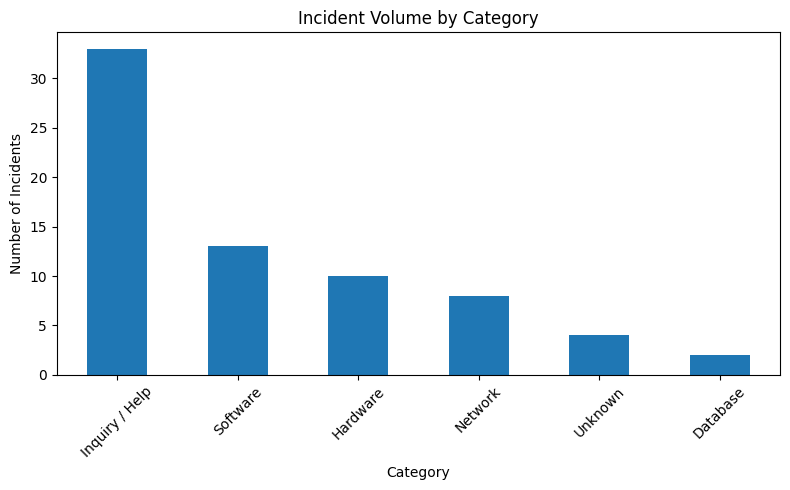

In [37]:
import matplotlib.pyplot as plt

category_counts = df['category'].fillna('Unknown').value_counts()

plt.figure(figsize=(8, 5))
category_counts.plot(kind='bar')

plt.title('Incident Volume by Category')
plt.xlabel('Category')
plt.ylabel('Number of Incidents')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<Figure size 800x500 with 0 Axes>

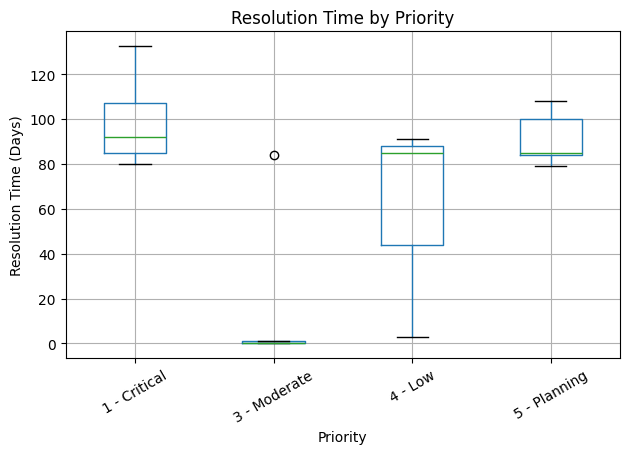

In [38]:
resolution_data = df[df['resolution_days'].notna()].copy()

plt.figure(figsize=(8, 5))

resolution_data.boxplot(
    column='resolution_days',
    by='priority'
)

plt.title('Resolution Time by Priority')
plt.suptitle('')
plt.xlabel('Priority')
plt.ylabel('Resolution Time (Days)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

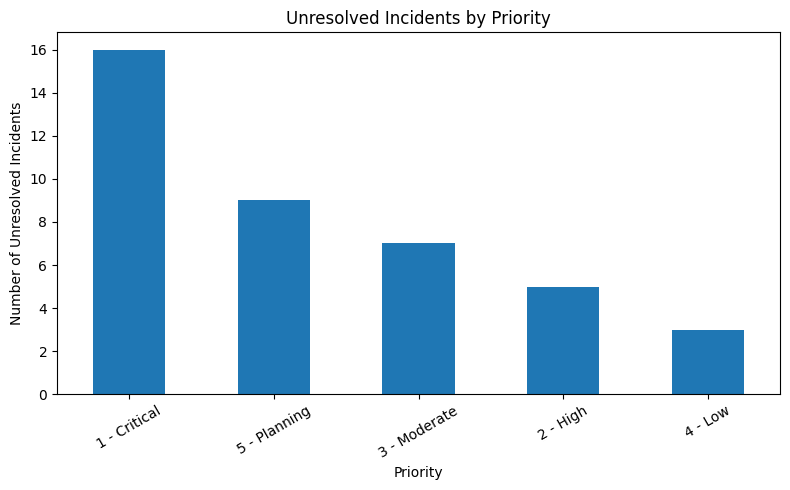

In [39]:
backlog = df[~df['state'].isin(['Closed', 'Resolved'])]

backlog_priority = backlog['priority'].value_counts()

plt.figure(figsize=(8, 5))
backlog_priority.plot(kind='bar')

plt.title('Unresolved Incidents by Priority')
plt.xlabel('Priority')
plt.ylabel('Number of Unresolved Incidents')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

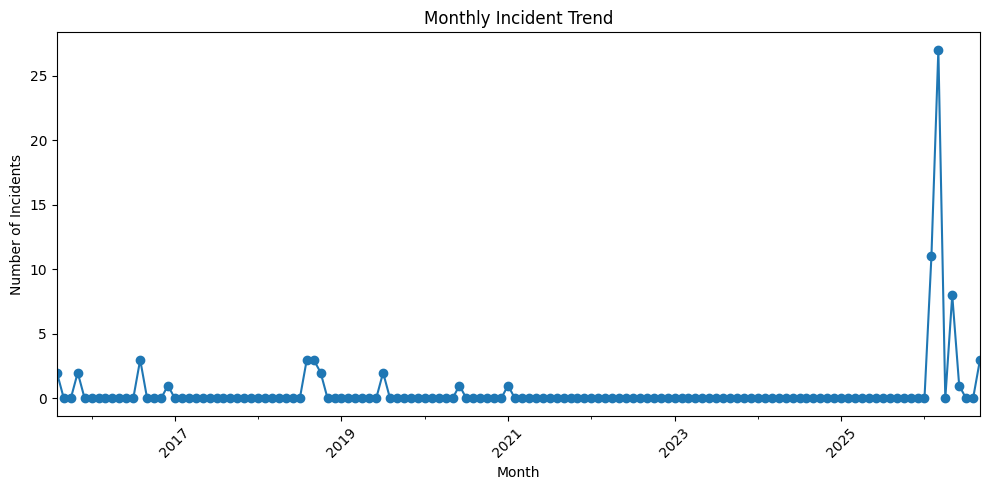

In [40]:
monthly_incidents = (
    df.set_index('opened_at')
      .resample('MS')
      .size()
)

plt.figure(figsize=(10, 5))
monthly_incidents.plot(kind='line', marker='o')

plt.title('Monthly Incident Trend')
plt.xlabel('Month')
plt.ylabel('Number of Incidents')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. Key Business Findings

- The dataset contains 70 incidents with no duplicate incident numbers or duplicate rows.
- Inquiry / Help is the largest incident category in the dataset.
- A significant portion of the unresolved backlog is concentrated in high-priority incidents.
- Resolution time varies considerably across priorities and categories.
- The dataset contains unusually old historical records, so resolution-time and backlog findings should be interpreted cautiously.
- March 2026 shows the highest incident volume in the dataset.
- Python/Pandas was used to prepare the data, calculate operational KPIs, perform exploratory analysis, and visualize incident trends.

## 7. Conclusion

The analysis transforms ServiceNow incident data into actionable IT support insights.
The results can be used to understand incident volume, priority, backlog,
assignment workload, resolution performance, and historical trends.

The cleaned and analyzed dataset will be used as the source for the Power BI
analytics dashboard.